# Intrinsic Neural Timescales — Schematic Figure

Synthetic data schematic illustrating the SA-axis gradient in intrinsic neural timescales:
three regions sampled from the bottom, middle, and top of the S-A axis, with their
corresponding simulated BOLD timeseries and ACFs (INT = AUC until zero-crossing).

Needs only `data/supporting_data/schaefer400-7_sa-axis.npy`; the fsaverage surface and Schaefer atlas are
fetched by nilearn on first run.

In [1]:
import os
import warnings
warnings.simplefilter("ignore", UserWarning)

import numpy as np

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.colors as mcolors
from nilearn import datasets, plotting, surface

from src.data import project_root
from src.plotting import figure_scratch_dir, setup_notebook_style
from snaplab_tools.plotting.utils import save_panel

%matplotlib inline

setup_notebook_style()

In [2]:
# Schematic is dataset-agnostic -> scratch dir has no /<dataset> suffix.
fig_dir = figure_scratch_dir()          # spans datasets: no per-dataset subdirectory

In [3]:
# ── SA-axis colormap (orange → white → purple) ─────────────────────────────
sa_cmap = mcolors.LinearSegmentedColormap.from_list(
    'sydnor_sa',
    [(0.0, '#FFA500'), (0.5, '#FFFFFF'), (1.0, '#8A2BE2')],
    N=256
)
try:
    plt.colormaps.register(cmap=sa_cmap, name='sydnor_sa')
except Exception:
    pass

# Three colormap positions (near-bottom, mid-high, near-top), avoiding pure white at 0.5 for visibility.
cmap_pos = [0.08, 0.68, 0.92]
region_colors = [sa_cmap(p) for p in cmap_pos]
region_labels = ['Sensorimotor (low S-A)', 'Transitional (mid S-A)', 'Association (high S-A)']

print('Region colors (RGBA):')
for lbl, c in zip(region_labels, region_colors):
    print(f'  {lbl.split(chr(10))[0]}: {mcolors.to_hex(c)}')

Region colors (RGBA):
  Sensorimotor (low S-A): #ffb328
  Transitional (mid S-A): #d4b2f4
  Association (high S-A): #9c4ce7


In [4]:
# ── Load SA-axis parcel data (Schaefer 400, 7 networks) ────────────────────
data_dir = os.path.join(project_root(), 'data', 'supporting_data')
sa_axis = np.load(os.path.join(data_dir, 'schaefer400-7_sa-axis.npy'))

# LH parcels: indices 0-199 (atlas labels 1-200)
sa_lh = sa_axis[:200]
sa_lh_rank = np.argsort(sa_lh)

# Select indices at ~5th, 50th, 95th percentile of LH SA axis
pct_targets = [0.05, 0.50, 0.95]
parcel_indices = [sa_lh_rank[int(p * len(sa_lh_rank))] for p in pct_targets]
atlas_labels   = [idx + 1 for idx in parcel_indices]  # 1-indexed atlas labels

# Normalize the full SA axis to [0, 1] for colormap
sa_min, sa_max = sa_axis.min(), sa_axis.max()
sa_norm = (sa_axis - sa_min) / (sa_max - sa_min)

print('Selected LH parcels:')
for i, (pidx, albl, pct) in enumerate(zip(parcel_indices, atlas_labels, pct_targets)):
    print(f'  Region {i+1} ({pct*100:.0f}th pct): parcel_idx={pidx}, atlas_label={albl}, '
          f'SA={sa_lh[pidx]:.0f}, SA_norm={sa_norm[pidx]:.3f}')

Selected LH parcels:
  Region 1 (5th pct): parcel_idx=10, atlas_label=11, SA=4356, SA_norm=0.057
  Region 2 (50th pct): parcel_idx=1, atlas_label=2, SA=30846, SA_norm=0.513
  Region 3 (95th pct): parcel_idx=141, atlas_label=142, SA=54546, SA_norm=0.921


In [5]:
# ── Project Schaefer 400 onto fsaverage5 and build highlight maps ──────────
fsavg = datasets.fetch_surf_fsaverage('fsaverage5')
parc  = datasets.fetch_atlas_schaefer_2018(n_rois=400, yeo_networks=7, resolution_mm=2)

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    surf_lh = np.round(
        surface.vol_to_surf(parc.maps, fsavg.pial_left, interpolation='nearest')
    ).astype(int)
    surf_rh = np.round(
        surface.vol_to_surf(parc.maps, fsavg.pial_right, interpolation='nearest')
    ).astype(int)

# Check that the selected parcels actually appear on the LH surface
for albl in atlas_labels:
    n_verts = np.sum(surf_lh == albl)
    print(f'  Atlas label {albl}: {n_verts} vertices on LH surface')

# Highlight map: NaN everywhere except 3 selected parcels
highlight_lh = np.full(len(surf_lh), np.nan)
for albl, cpos in zip(atlas_labels, cmap_pos):
    highlight_lh[surf_lh == albl] = cpos

print(f'\nNon-NaN highlight vertices: {np.sum(~np.isnan(highlight_lh))}')

[fetch_atlas_schaefer_2018] Dataset found in /home/lindenmp/nilearn_data/schaefer_2018

  Atlas label 11: 51 vertices on LH surface
  Atlas label 2: 76 vertices on LH surface
  Atlas label 142: 53 vertices on LH surface

Non-NaN highlight vertices: 180


In [6]:
# ── Full SA-axis vertex texture (all 400 parcels) ──────────────────────────
# Each surface vertex takes the normalised SA value of its Schaefer parcel, with background and medial-wall
# vertices left NaN.
sa_vertex_lh = np.full(len(surf_lh), np.nan)
mask_lh = surf_lh > 0
sa_vertex_lh[mask_lh] = sa_norm[surf_lh[mask_lh] - 1]

sa_vertex_rh = np.full(len(surf_rh), np.nan)
mask_rh = surf_rh > 0
sa_vertex_rh[mask_rh] = sa_norm[surf_rh[mask_rh] - 1]

print(f'LH: {np.sum(~np.isnan(sa_vertex_lh))} / {len(sa_vertex_lh)} vertices coloured')
print(f'RH: {np.sum(~np.isnan(sa_vertex_rh))} / {len(sa_vertex_rh)} vertices coloured')

LH: 9498 / 10242 vertices coloured
RH: 9536 / 10242 vertices coloured


In [7]:
# ── Simulate synthetic BOLD timeseries (AR(1) processes) ──────────────────
TR   = 0.72   # seconds
N_TP = 400    # timepoints
time = np.arange(N_TP) * TR

def simulate_ar1(n, phi, seed):
    """Unit-variance AR(1) process."""
    rng   = np.random.default_rng(seed)
    noise = rng.normal(0, np.sqrt(1 - phi**2), n)
    x = np.zeros(n)
    for t in range(1, n):
        x[t] = phi * x[t-1] + noise[t]
    x = (x - x.mean()) / x.std()
    return x

# phi / seed pairs chosen to give empirical INTs ≈ 2, 4, 6 seconds
phi_values = [0.70, 0.890, 0.95]
seeds      = [42,   42,    195]
timeseries = [simulate_ar1(N_TP, phi, seed) for phi, seed in zip(phi_values, seeds)]

In [8]:
# ── Compute ACFs and INTs (AUC to zero-crossing) ───────────────────────────
MAX_LAG = 50  # lags to display

def compute_acf(ts, max_lag):
    n    = len(ts)
    std  = (ts - ts.mean()) / ts.std()
    full = np.correlate(std, std, mode='full')
    acf  = full[n-1:n+max_lag] / full[n-1]
    return acf

def zero_crossing(acf):
    """First lag index where ACF crosses zero (goes negative)."""
    neg = np.where(acf < 0)[0]
    return neg[0] if len(neg) > 0 else len(acf) - 1

def int_auc(acf, zc_lag, tr):
    """Trapezoidal AUC from lag 0 to zero-crossing."""
    return float(np.sum(acf[:zc_lag + 1]) * tr)

acfs    = [compute_acf(ts, MAX_LAG) for ts in timeseries]
zc_lags = [zero_crossing(acf) for acf in acfs]
ints    = [int_auc(acf, zc, TR) for acf, zc in zip(acfs, zc_lags)]

print('Empirical INTs from synthetic data:')
for i, (phi, zc, int_val) in enumerate(zip(phi_values, zc_lags, ints)):
    print(f'  Region {i+1}: phi={phi}, zero-crossing lag={zc} ({zc*TR:.2f}s), INT={int_val:.2f}s')

Empirical INTs from synthetic data:
  Region 1: phi=0.7, zero-crossing lag=8 (5.76s), INT=1.88s
  Region 2: phi=0.89, zero-crossing lag=18 (12.96s), INT=4.09s
  Region 3: phi=0.95, zero-crossing lag=37 (26.64s), INT=9.55s


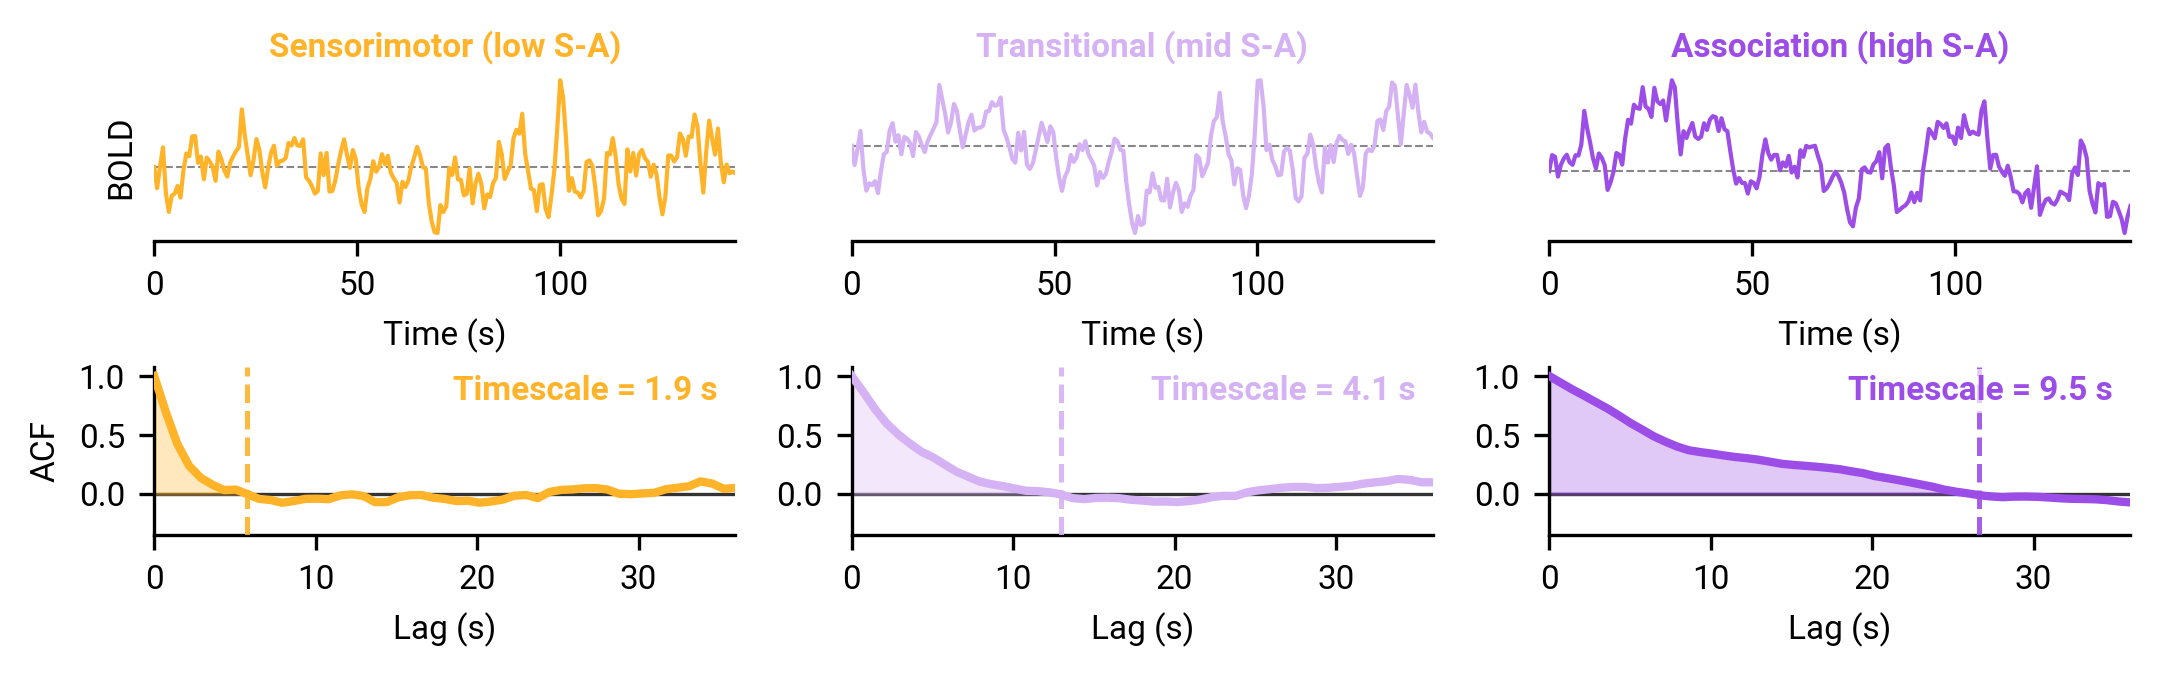

In [9]:
PLOT_BRAIN = False   # ← toggle: True = include SA-axis brain panel on left

import warnings

# ── Figure & gridspec ──────────────────────────────────────────────────────
if PLOT_BRAIN:
    fig = plt.figure(figsize=(15, 5), facecolor='white')
    gs  = gridspec.GridSpec(1, 2, figure=fig,
                            width_ratios=[1.4, 2.5], wspace=0.12)

    # Left section: 2 brain views (top) + colorbar strip (bottom)
    gs_brain = gridspec.GridSpecFromSubplotSpec(
        2, 2, subplot_spec=gs[0],
        height_ratios=[12, 1], hspace=0.06, wspace=0.0
    )
    ax_lh   = fig.add_subplot(gs_brain[0, 0], projection='3d')
    ax_rh   = fig.add_subplot(gs_brain[0, 1], projection='3d')
    ax_cbar = fig.add_subplot(gs_brain[1, :])

    # Brain surface plots — flat parcel colours, no sulcal shading
    brain_kw = dict(bg_map=None, cmap=sa_cmap, vmin=0, vmax=1,
                    colorbar=False, figure=fig)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        plotting.plot_surf_stat_map(
            fsavg.infl_left,  sa_vertex_lh, hemi='left',  view='lateral',
            axes=ax_lh, **brain_kw)
        plotting.plot_surf_stat_map(
            fsavg.infl_right, sa_vertex_rh, hemi='right', view='lateral',
            axes=ax_rh, **brain_kw)

    # Centered title spanning both brain axes
    ax_lh.text2D(1.0, 1.10, 'Sensorimotor-Association Axis',
                 transform=ax_lh.transAxes,
                 fontsize=11, ha='center', va='bottom')

    # Panel label A
    ax_lh.text2D(-0.05, 1.08, 'A', transform=ax_lh.transAxes,
                 fontsize=14, fontweight='bold', va='top')

    # Colorbar strip
    ax_cbar.imshow(np.linspace(0, 1, 256).reshape(1, -1),
                   aspect='auto', cmap=sa_cmap)
    ax_cbar.set_xticks([])
    ax_cbar.set_yticks([])
    for sp in ax_cbar.spines.values():
        sp.set_visible(False)
    ax_cbar.text(-0.01, 0.5,
                 'Sensorimotor Pole\n$\\it{low\\ rank}$',
                 transform=ax_cbar.transAxes,
                 fontsize=8, ha='right', va='center')
    ax_cbar.text(1.01, 0.5,
                 'Association Pole\n$\\it{high\\ rank}$',
                 transform=ax_cbar.transAxes,
                 fontsize=8, ha='left', va='center')

    gs_right = gridspec.GridSpecFromSubplotSpec(
        2, 3, subplot_spec=gs[1], hspace=0.45, wspace=0.2)
else:
    fig = plt.figure(figsize=(8.5, 2), facecolor='white')
    gs_right = gridspec.GridSpec(2, 3, figure=fig, hspace=0.75, wspace=0.2)

ax_ts  = [fig.add_subplot(gs_right[0, i]) for i in range(3)]
ax_acf = [fig.add_subplot(gs_right[1, i]) for i in range(3)]

N_SHOW = 200
t_show = time[:N_SHOW]

# ── Timeseries ─────────────────────────────────────────────────────────────
for i, (ts, color, lbl) in enumerate(zip(timeseries, region_colors, region_labels)):
    ax = ax_ts[i]
    ax.plot(t_show, ts[:N_SHOW], color=color, linewidth=1.0, rasterized=True)
    ax.axhline(0, color='#888888', linewidth=0.5, linestyle='--', zorder=0)
    ax.set_xlim(t_show[0], t_show[-1])
    ax.set_xlabel('Time (s)', fontsize=8)
    ax.set_yticks([])
    ax.spines['left'].set_visible(False)
    ax.tick_params(axis='x', labelsize=8)
    ax.set_title(lbl, fontsize=8, color=color, fontweight='bold', pad=4)

ax_ts[0].set_ylabel('BOLD', fontsize=8)
# ax_ts[0].text(-0.18, 1.18, 'A', transform=ax_ts[0].transAxes,
            #   fontsize=14, fontweight='bold', va='top')

# ── ACF plots ──────────────────────────────────────────────────────────────
lags_s = np.arange(MAX_LAG + 1) * TR

for i, (acf, zc, int_val, color) in enumerate(
    zip(acfs, zc_lags, ints, region_colors)
):
    ax   = ax_acf[i]
    zc_s = zc * TR

    ax.plot(lags_s, acf, color=color, linewidth=2.0, zorder=3)
    ax.fill_between(lags_s[:zc + 1], 0, acf[:zc + 1],
                    color=color, alpha=0.30, zorder=2)
    ax.axhline(0, color='#333333', linewidth=0.8, zorder=1)
    ax.axvline(zc_s, color=color, linewidth=1.2, linestyle='--', alpha=0.9, zorder=4)

    # INT annotation: top-right corner of each axis
    ax.text(0.97, 0.95, f'Timescale = {int_val:.1f} s',
            transform=ax.transAxes,
            color=color, fontsize=8, fontweight='bold',
            ha='right', va='top', zorder=5,
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.7, pad=1.5))

    ax.set_xlim(0, lags_s[-1])
    ax.set_ylim(-0.35, 1.08)
    ax.set_yticks([0, 0.5, 1])
    ax.set_xlabel('Lag (s)', fontsize=8)
    ax.tick_params(labelsize=8)

ax_acf[0].set_ylabel('ACF', fontsize=8)
# ax_acf[0].text(-0.18, 1.18, 'B', transform=ax_acf[0].transAxes,
            #    fontsize=14, fontweight='bold', va='top')

# fig.tight_layout()
save_panel(plt.gcf(), fig_dir, 'timescales_schematic', transparent=True)
plt.show()